# Fake fluid of the velocity field

**The idea.**
1. In every cell, at every time step, the fluid the cell gained must equal the fluid that came in through its walls minus what went out.
2. The solver satisfies this exactly, using its own wall flows.
3. We repeat the bookkeeping using instead the **velocity field we would give to the transport equation**.
4. Whatever does not balance is **fake fluid**, created or destroyed by that velocity. In the transport it would become fake solute.

Per cell $K$ and per unit time:

$$\text{fake}_K = \underbrace{\text{gained}_K + \text{wall flow out}_K(\text{velocity})}_{\neq 0} = \text{wall flow out}_K(\text{velocity}) - \text{wall flow out}_K(\text{solver}).$$

**The three velocities tested**, for each model:

| | end-of-step velocity | step-average velocity | reconstructed velocity |
|---|---|---|---|
| 2F | $-\kappa\nabla p^{n+1}$ | $\theta q^{n+1} + (1-\theta)\,q^n$ | H(div) field of `biotx.flux` |
| 3F | $\dot w^{n+1}$ (Morasca's choice) | $(w^{n+1} - w^n)/\Delta t$ | H(div) field of `biotx.flux` |

The fluid moved during a step is the step-average velocity times $\Delta t$, so the step average is right in time, and the end-of-step velocity adds an error in time. Both share the error in space: on a wall between two cells, the value from each side differs. The reconstructed velocity (Step 2) is built so that its flow through every wall *is* the solver's: its fake fluid should be round-off.

**The case.** The annulus with the brain parameters, P2, $\Delta t$ = 10 ms, 3 s from rest, mesh $h$ = 0.5 mm unless stated. The formulas for each term are in the docstring of `balance.py`. To recompute: `python balance.py ../annulus_biot2.yaml --set geometry.h=5.0e-4 --name annulus_biot2_0.5mm`, or `RERUN = True` below (about 4 minutes in total).

In [1]:
from pathlib import Path
import subprocess, sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FormatStrFormatter, NullLocator
from matplotlib.collections import PolyCollection
from matplotlib.colors import TwoSlopeNorm

RERUN = False
H = {"2mm": 2.0e-3, "1mm": 1.0e-3, "0.5mm": 5.0e-4}
COLORS = {"biot2": "#2a78d6", "biot3": "#eb6834"}          # the colours of the conditioning notebook
MARKERS = {"biot2": "o", "biot3": "^"}
MODEL = {"biot2": "2F", "biot3": "3F"}
VEL = {"end": "end-of-step velocity", "avg": "step-average velocity", "rec": "reconstructed velocity"}
LS = {"end": "-", "avg": "--", "rec": ":"}


def get(model, tag="0.5mm", zeta=None):
    name = f"annulus_{model}_{tag}" + (f"_zeta{zeta:.1f}" if zeta else "")
    path = Path("results") / f"{name}.npz"
    if RERUN or not path.exists():
        cmd = [sys.executable, "balance.py", f"../annulus_{model}.yaml", "--set", f"geometry.h={H[tag]}", "--name", name]
        if zeta:
            cmd += ["--set", f"discretization.zeta={zeta}"]
        subprocess.run(cmd, check=True)
    r = dict(np.load(path, allow_pickle=True))
    r["h_eff"] = np.sqrt(r["volume"].sum() / len(r["volume"]))
    r["last"] = r["t"] > r["t"][-1] - float(r["period"]) + 0.5 * float(r["dt"])     # the last period
    return r


R = {(m, tag): get(m, tag) for m in ("biot2", "biot3") for tag in H}
B2, B3 = R[("biot2", "0.5mm")], R[("biot3", "0.5mm")]

## 1. Check: with the solver's wall flows, the books balance

$\max_K |\text{gained}_K + \text{wall flow out}_K(\text{solver})|$, relative to the largest cell throughput, over all steps. Round-off means the bookkeeping is right, so every mismatch below comes from the velocity.

In [2]:
for (m, tag), r in R.items():
    print(f"{MODEL[m]}, h = {tag:5s}: {r['solver_check'].max():.1e}")

2F, h = 2mm  : 4.6e-13
2F, h = 1mm  : 9.0e-13
2F, h = 0.5mm: 2.0e-12
3F, h = 2mm  : 6.2e-12
3F, h = 1mm  : 5.6e-12
3F, h = 0.5mm: 1.3e-11


## 2. One cell's books

One cell at $t$ = 2.5 s: the 2F cell with the largest fake fluid relative to its throughput, and the same cell in 3F (the mesh is the same). Flows in m²/s per unit depth, positive out of the cell.

In [3]:
i = int(np.argmin(np.abs(B2["map_t"] - 2.5)))
tp = B2["map_throughput"][i]
k = int(np.argmax(np.abs(B2["map_wall_avg"][i] - B2["map_wall_solver"][i]) / tp))
centre = B2["x"][B2["cells"][k]].mean(axis=0)
print(f"cell {k}, centre ({centre[0] * 1e3:.2f}, {centre[1] * 1e3:.2f}) mm, t = {B2['map_t'][i]:.2f} s\n")
for m, r in (("biot2", B2), ("biot3", B3)):
    g, ws = r["map_gained"][i][k], r["map_wall_solver"][i][k]
    print(f"{MODEL[m]}: throughput {r['map_throughput'][i][k]:.3e}")
    print(f"    gained                     {g:+.6e}")
    for name, w in (("solver", ws), ("end-of-step velocity", r["map_wall_end"][i][k]),
                    ("step-average velocity", r["map_wall_avg"][i][k]),
                    ("reconstructed velocity", r["map_wall_rec"][i][k])):
        print(f"    wall flow out, {name:22s}{w:+.6e}   gained + out = {g + w:+.3e}"
              f"   ({abs(g + w) / r['map_throughput'][i][k]:.1e} of the throughput)")
    print()

cell 996, centre (-1.08, -2.95) mm, t = 2.50 s

2F: throughput 1.614e-07
    gained                     +1.818375e-11
    wall flow out, solver                -1.818375e-11   gained + out = +3.621e-20   (2.2e-13 of the throughput)
    wall flow out, end-of-step velocity  -5.565629e-09   gained + out = -5.547e-09   (3.4e-02 of the throughput)
    wall flow out, step-average velocity -5.537936e-09   gained + out = -5.520e-09   (3.4e-02 of the throughput)
    wall flow out, reconstructed velocity-1.818375e-11   gained + out = +1.822e-20   (1.1e-13 of the throughput)

3F: throughput 1.616e-07
    gained                     +1.821632e-11
    wall flow out, solver                -1.821632e-11   gained + out = +2.380e-21   (1.5e-14 of the throughput)
    wall flow out, end-of-step velocity  -2.159114e-11   gained + out = -3.375e-12   (2.1e-05 of the throughput)
    wall flow out, step-average velocity -1.821178e-11   gained + out = +4.531e-15   (2.8e-08 of the throughput)
    wall flow out, r

## 3. Main result

Over the last period ($t \in [2, 3]$ s), for each velocity:
- **fake / throughput, all cells:** $\sum_K|\text{fake}_K| / \sum_K \text{throughput}_K$, averaged over the period;
- **worst cell:** $\max_K |\text{fake}_K| / \text{throughput}_K$, the largest over the period;
- **drift in 80 s:** how much a unit concentration would change over Morasca's 80 s of transport in the worst cell, if the fake source acted alone ($80\,\mathrm{s} \times \max_K |\text{fake}_K|/|K|$). A rough, worst-case size.

In [4]:
rows = [["model", "velocity", "fake / throughput, all cells", "worst cell", "drift in 80 s"]]
for m, r in (("biot2", B2), ("biot3", B3)):
    for v in ("end", "avg", "rec"):
        rows.append([MODEL[m], VEL[v], f"{r[f'{v}_total'][r['last']].mean():.1e}",
                     f"{r[f'{v}_worst'][r['last']].max():.1e}", f"{r[f'{v}_drift80'][r['last']].max():.1e}"])
w = [max(len(row[j]) for row in rows) for j in range(len(rows[0]))]
for row in rows:
    print("  " + "  ".join(c.ljust(wj) for c, wj in zip(row, w)))

  model  velocity                fake / throughput, all cells  worst cell  drift in 80 s
  2F     end-of-step velocity    5.2e-03                       3.7e+00     4.1e+00      
  2F     step-average velocity   3.1e-03                       2.1e-01     4.1e+00      
  2F     reconstructed velocity  1.2e-13                       5.7e-11     1.1e-10      
  3F     end-of-step velocity    2.7e-03                       6.3e+00     2.0e-02      
  3F     step-average velocity   3.7e-06                       8.7e-03     6.3e-05      
  3F     reconstructed velocity  3.2e-14                       1.3e-10     2.8e-12      


## 4. In time

Fake fluid over all cells, relative to the throughput, at every step. Grey: the solver's own books (round-off).

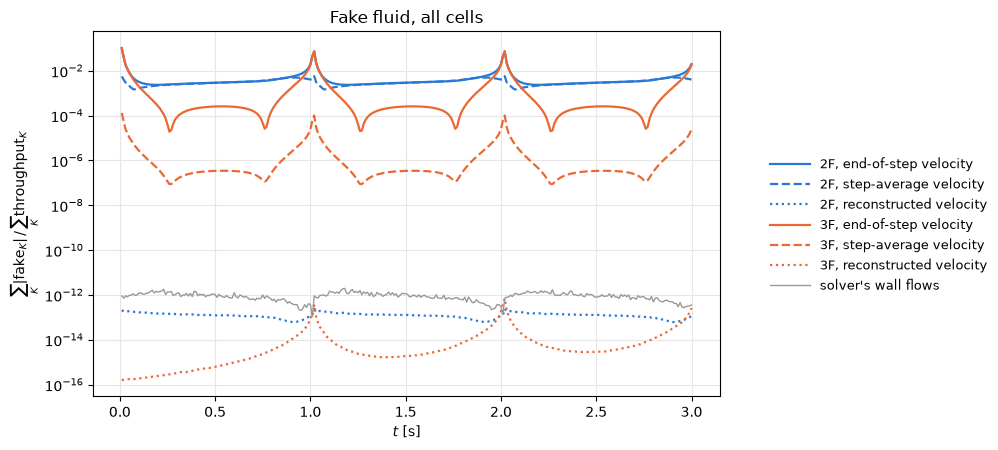

In [5]:
def style(ax, xlabel, ylabel, title, legend=True):
    ax.grid(True, which="both", color="0.9")
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    if legend:
        ax.legend(frameon=False, fontsize=9, handlelength=3.2)


fig, ax = plt.subplots(figsize=(10, 4.6))
for m, r in (("biot2", B2), ("biot3", B3)):
    for v in ("end", "avg", "rec"):
        ax.semilogy(r["t"], r[f"{v}_total"], LS[v], color=COLORS[m], lw=1.6, label=f"{MODEL[m]}, {VEL[v]}")
ax.semilogy(B2["t"], B2["solver_check"], color="0.6", lw=1, label="solver's wall flows")
style(ax, "$t$ [s]", "$\\sum_K |\\mathrm{fake}_K| \\,/\\, \\sum_K \\mathrm{throughput}_K$", "Fake fluid, all cells", legend=False)
fig.legend(*ax.get_legend_handles_labels(), loc="center right", frameon=False, fontsize=9, handlelength=3.2)
fig.tight_layout(rect=(0, 0, 0.74, 1))
plt.show()

## 5. Where: map at $t$ = 2.5 s

$\text{fake}_K / \text{throughput}_K$ with the step-average velocity. Red: the velocity takes out fluid that is not there; blue: it brings in fluid from nowhere. Mind the colour scales: about $3\cdot10^{-2}$ for 2F, $10^{-6}$ for 3F (on a shared scale 3F would look blank).

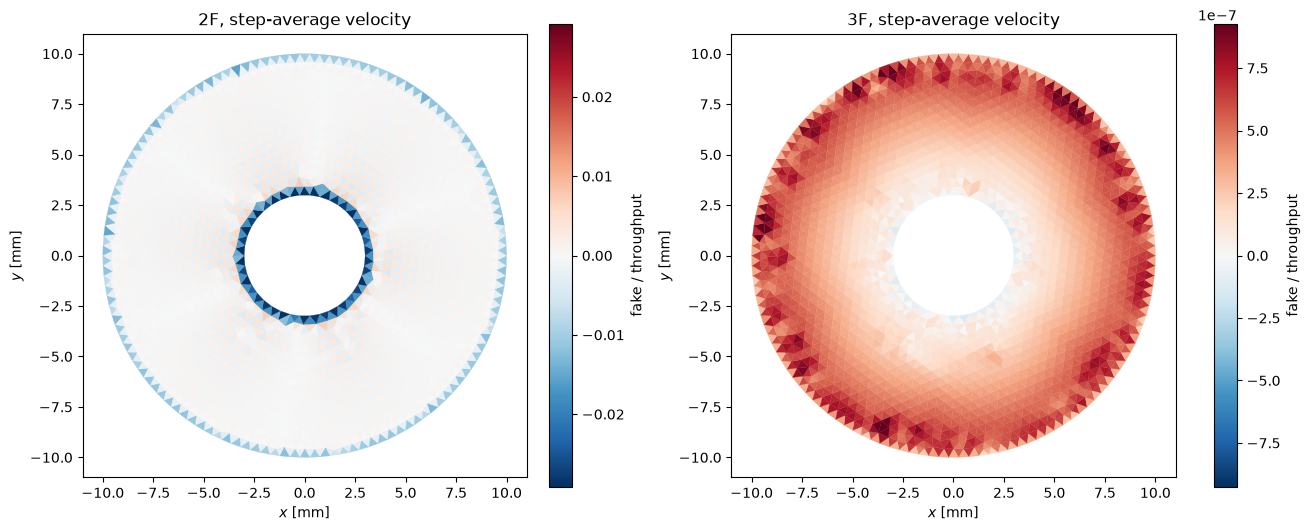

In [6]:
def cellmap(ax, r, values, title, lim):
    pc = PolyCollection(r["x"][r["cells"]] * 1e3, array=values, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim),
                        edgecolors="face", linewidths=0.2)
    ax.add_collection(pc)
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set(xlabel="$x$ [mm]", ylabel="$y$ [mm]", title=title)
    return pc


rel = {}
for m, r in (("biot2", B2), ("biot3", B3)):
    i = int(np.argmin(np.abs(r["map_t"] - 2.5)))
    rel[m] = (r["map_wall_avg"][i] - r["map_wall_solver"][i]) / r["map_throughput"][i]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), layout="constrained")
for ax, (m, r) in zip(axes, (("biot2", B2), ("biot3", B3))):    # each model its own scale
    pc = cellmap(ax, r, rel[m], f"{MODEL[m]}, step-average velocity", np.quantile(np.abs(rel[m]), 0.995))
    fig.colorbar(pc, ax=ax, shrink=0.85, label="fake / throughput")
plt.show()

## 6. The fix: the reconstructed velocity (Step 2)

`biotx.flux.Reconstruction` builds, after each solve, a Raviart–Thomas velocity whose flow through every wall is the solver's own wall flow over the step, and which follows the raw velocity inside each cell. Its fake fluid is the third row of each model in the tables above, and the dotted lines in the time plot: round-off, in both models, at every step. It costs nothing in accuracy: on manufactured solutions it converges at the same order as the raw velocity, with nearly the same error (`tests/test_flux.py`).

## 7. Reading the results

- **The bookkeeping is right.** With the solver's wall flows every cell balances to $10^{-12}$–$10^{-11}$.
- **2F: the raw velocity $-\kappa\nabla p_h$ makes fake fluid.**
  - About 0.3 % of everything flowing through the cells, and up to 20 % in the worst cells.
  - The worst-cell drift over 80 s is about 4 for a unit concentration.
  - Most of it sits in the cells along the cavity and the outer wall.
  - It is in space: the gradient seen from the two sides of a wall differs.
- **3F: the raw step-average velocity is nearly clean** ($4\cdot10^{-6}$). The end-of-step velocity $\dot w^{n+1}$ is about 1000 times worse, an error in time.
- **The reconstructed velocity removes the fake fluid in both models,** to round-off: this is the velocity to give the transport equation.

---
# Appendix

## A. Under mesh refinement

Fake fluid over all cells (period mean) against $h_{\mathrm{eff}} = (|\Omega|/N_{\mathrm{cells}})^{1/2}$. The legend gives the slope of the last refinement.

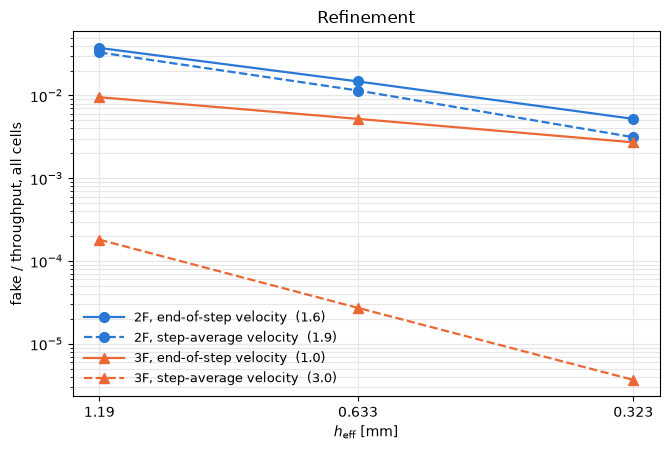

In [7]:
fig, ax = plt.subplots(figsize=(6.8, 4.6))
for m in ("biot2", "biot3"):
    hs = np.array([R[(m, t)]["h_eff"] for t in H]) * 1e3
    for v in ("end", "avg"):
        y = np.array([R[(m, t)][f"{v}_total"][R[(m, t)]["last"]].mean() for t in H])
        sl = np.log(y[-1] / y[-2]) / np.log(hs[-1] / hs[-2])
        ax.loglog(hs, y, LS[v], marker=MARKERS[m], color=COLORS[m], lw=1.6, ms=7, label=f"{MODEL[m]}, {VEL[v]}  ({sl:.1f})")
ax.invert_xaxis()
ax.xaxis.set_major_locator(FixedLocator(hs))
ax.xaxis.set_major_formatter(FormatStrFormatter("%.3g"))
ax.xaxis.set_minor_locator(NullLocator())
style(ax, "$h_{\\mathrm{eff}}$ [mm]", "fake / throughput, all cells", "Refinement")
fig.tight_layout()
plt.show()

2F falls like $h^{1.9}$: refining helps, but each halving costs 4 times the cells in 2D (8 in 3D). 3F's step-average velocity falls like $h^3$. Its end-of-step velocity falls only like $h^1$, because its error is in time.

## B. Averaged over the heartbeat (what Morasca fed to the transport)

The solution is periodic to $10^{-11}$ after two cycles. Over one period the fluid in each cell returns to its start, so the averaged solver flow is zero through every cell, and a correct averaged velocity must give no fake fluid. Below are the averages over the last period: the fake fluid of the averaged velocities, and the worst-cell drift in 80 s if the averaged velocity is used for the whole transport.

In [8]:
rows = [["model", "velocity", "fake / throughput (median cell)", "drift in 80 s (worst cell)"]]
for m, r in (("biot2", B2), ("biot3", B3)):
    tp = r["period_throughput"]
    rows.append([MODEL[m], "solver (net, periodicity)", f"{np.median(np.abs(r['period_gained']) / tp):.1e}", ""])
    for v in ("end", "avg", "rec"):
        fake = r[f"period_wall_{v}"] - r["period_wall_solver"]
        rows.append([MODEL[m], VEL[v], f"{np.median(np.abs(fake) / tp):.1e}",
                     f"{80 * (np.abs(fake) / r['volume']).max():.1e}"])
w = [max(len(row[j]) for row in rows) for j in range(len(rows[0]))]
for row in rows:
    print("  " + "  ".join(c.ljust(wj) for c, wj in zip(row, w)))

  model  velocity                   fake / throughput (median cell)  drift in 80 s (worst cell)
  2F     solver (net, periodicity)  2.5e-12                                                    
  2F     end-of-step velocity       8.7e-04                          2.1e+00                   
  2F     step-average velocity      8.7e-04                          2.1e+00                   
  2F     reconstructed velocity     4.1e-14                          1.9e-11                   
  3F     solver (net, periodicity)  2.0e-12                                                    
  3F     end-of-step velocity       1.6e-10                          1.2e-07                   
  3F     step-average velocity      3.9e-13                          1.5e-10                   
  3F     reconstructed velocity     1.3e-16                          3.0e-14                   


In 3F the time error of the end-of-step velocity cancels over a full period (the sums telescope), so the averaged field is clean. In 2F the error is in space and survives the average: the averaged $-\kappa\nabla p_h$ still drifts a unit concentration by about 2 in 80 s in the worst cell.

## C. Is it the Darcy penalty? (2F)

The solver's 2F wall flow includes the penalty $\zeta\tilde\kappa k^2/h_F\,[\![p]\!]$, which the gradient does not see, and $\tilde\kappa = \max(\kappa^*, 1)$ makes the penalty large. If the penalty caused the fake fluid, changing $\zeta$ would change it. Step-average velocity, last period. `boundary share` is the part of the fake fluid in the cells touching the cavity or the outer wall (12 % of the cells) at $t$ = 2.5 s.

In [9]:
def boundary_cells(r):
    rad = np.linalg.norm(r["x"], axis=1)                     # the annulus: radii 3 mm and 10 mm
    return ((np.abs(rad - 3e-3) < 1e-7) | (np.abs(rad - 1e-2) < 1e-7))[r["cells"]].any(axis=1)


print("  zeta   fake / throughput   worst cell   drift in 80 s   boundary share")
for z in (1.0, 10, 100.0):
    r = B2 if z == 10 else get("biot2", zeta=z)
    i = int(np.argmin(np.abs(r["map_t"] - 2.5)))
    fake = np.abs(r["map_wall_avg"][i] - r["map_wall_solver"][i])
    b = boundary_cells(r)
    print(f"  {z:5g}  {r['avg_total'][r['last']].mean():.1e}             {r['avg_worst'][r['last']].max():.1e}"
          f"      {r['avg_drift80'][r['last']].max():.1e}         {fake[b].sum() / fake.sum():.2f}")

  zeta   fake / throughput   worst cell   drift in 80 s   boundary share
      1  2.6e-03             1.9e-01      3.1e+00         0.58
     10  3.1e-03             2.1e-01      4.1e+00         0.63
    100  3.2e-03             2.1e-01      4.3e+00         0.63


A factor 100 in $\zeta$ changes the fake fluid by less than 25 %. As $\zeta$ grows the pressure jumps shrink, and the penalty part of the flow stays about the same. The fake fluid comes from the gradient itself, mostly along the boundaries.

## D. Global balance and wall jumps

Left: the net fake fluid over the whole domain, $|\sum_K \text{fake}_K|$ (m²/s per unit depth). Right: how much the velocity's normal component jumps across interior walls, $\|[\![q\cdot n]\!]\| / \|\{q\}\cdot n\|$. That jump is the origin of the fake fluid.

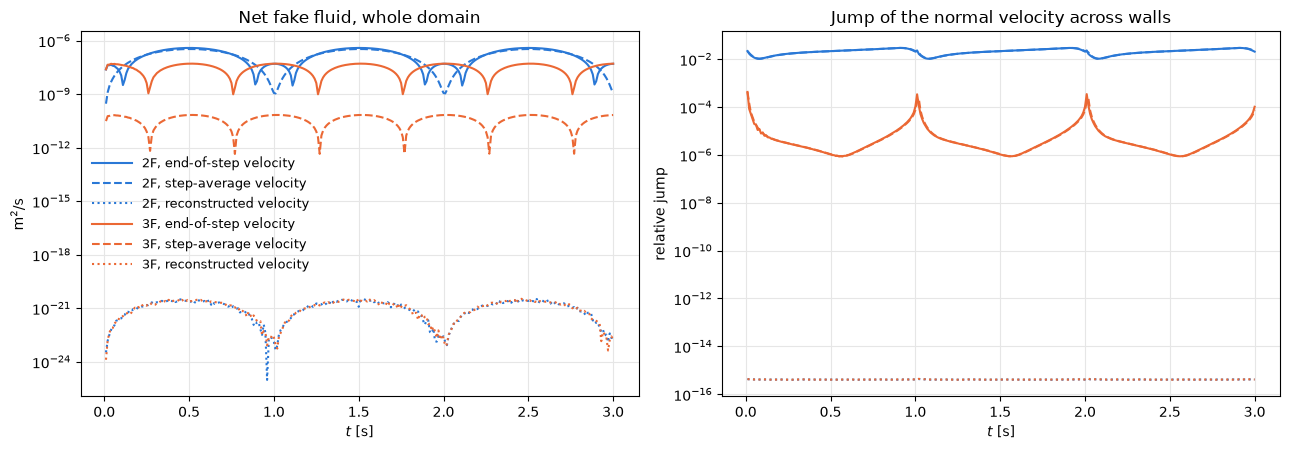

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, key in zip(axes, ("global", "jump")):
    for m, r in (("biot2", B2), ("biot3", B3)):
        for v in ("end", "avg", "rec"):
            ax.semilogy(r["t"], np.maximum(np.abs(r[f"{v}_{key}"]), 1e-30), LS[v], color=COLORS[m], lw=1.5,
                        label=f"{MODEL[m]}, {VEL[v]}")
style(axes[0], "$t$ [s]", "m$^2$/s", "Net fake fluid, whole domain")
style(axes[1], "$t$ [s]", "relative jump", "Jump of the normal velocity across walls", legend=False)
fig.tight_layout()
plt.show()

## E. Worst cell in time

$\max_K |\text{fake}_K| / \text{throughput}_K$ at every step. The spikes at $t$ = 1, 2, 3 s are the moments the pulse restarts, when the flows are near zero and any mismatch is large relative to them.

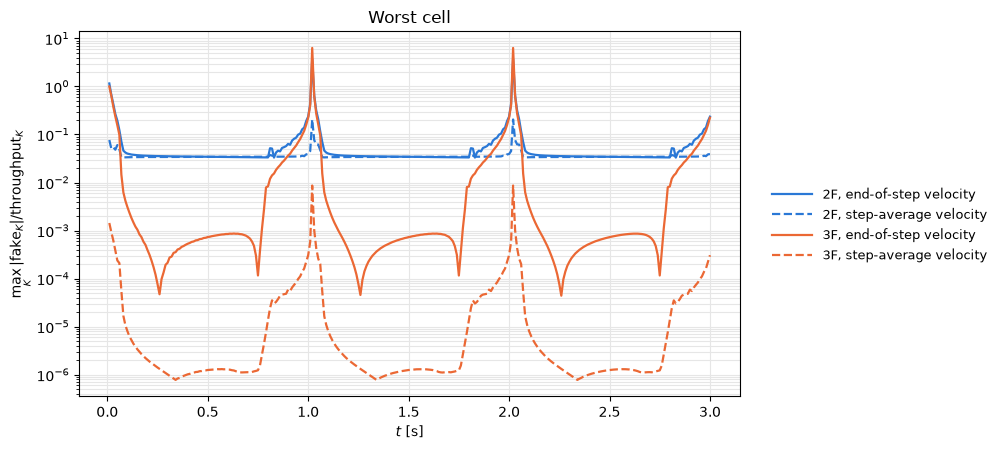

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.6))
for m, r in (("biot2", B2), ("biot3", B3)):
    for v in ("end", "avg"):
        ax.semilogy(r["t"], r[f"{v}_worst"], LS[v], color=COLORS[m], lw=1.6, label=f"{MODEL[m]}, {VEL[v]}")
style(ax, "$t$ [s]", "$\\max_K |\\mathrm{fake}_K| / \\mathrm{throughput}_K$", "Worst cell", legend=False)
fig.legend(*ax.get_legend_handles_labels(), loc="center right", frameon=False, fontsize=9, handlelength=3.2)
fig.tight_layout(rect=(0, 0, 0.76, 1))
plt.show()